# MoveInSync - Exploratory Data Analysis & Modeling

Hey! Welcome to the analysis notebook. 

In this notebook, I'll be exploring the Google Play Store reviews for the MoveInSync employee transport app (`com.moveinsync.ets`). Our main goal is to figure out **why the app is getting its current Play Store ratings** and build a model that can help us automatically classify new reviews.

First, let's bring in the libraries we'll need for this analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from datetime import datetime
import warnings

# Make matplotlib look a bit nicer
plt.style.use('seaborn-v0_8-whitegrid')
warnings.filterwarnings('ignore')


### 1. Loading the Data

Let's load up the raw dataset and take a quick peek at the first few rows to understand what we're working with.

In [2]:
raw_csv_path = '../data/raw/google_play_reviews.csv'
df_raw = pd.read_csv(raw_csv_path, dtype=str, low_memory=False)

print(f"Total reviews collected: {len(df_raw)}")
df_raw.head()


Total reviews collected: 10144


,review_id,app_id,review_text,star_rating,review_date,review_date_ts,last_updated,app_version,reviewer_id_hash,developer_reply,developer_reply_date,language,country,source_platform,sort_order,collection_timestamp
0,60798e45-939e-4a99-8f5b-17383a891db6,com.moveinsync.ets,"whenever i update this app, i am not able to o...",1,2026-10-09T10:55:03,1791523503.0,NaN,NaN,6058644320622310,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00
1,25c29e24-3832-4411-842b-8fb741ae64b7,com.moveinsync.ets,good,5,2026-10-09T09:14:34,1791517474.0,NaN,12.19.0,2f773f25a2e75e8b,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00
2,7476b129-f0da-458e-8f86-d77ba2f9a710,com.moveinsync.ets,MoveOutSync doesn't plan commutes; it plans cr...,1,2026-10-09T08:22:55,1791514375.0,NaN,12.19.0,7b56affacc72d077,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00
3,2b3d9423-1036-415c-bc42-f0a674de63d4,com.moveinsync.ets,Superb app and app functionalities,5,2026-10-09T07:49:38,1791512378.0,NaN,12.19.0,0d5f8ab19814da72,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00
4,b60783da-094d-45b3-94da-2b21618845e6,com.moveinsync.ets,very great app,5,2026-10-09T05:07:34,1791502654.0,NaN,12.20.0,6e54691a1fd74427,NaN,NaN,en,in,google_play,NEWEST,2026-10-10T07:44:01.612046+00:00


Looks like we have `review_id`, `review_text`, `star_rating`, and some date fields. 

Let's check the data types and see if there are any missing values.

In [3]:
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10144 entries, 0 to 10143
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   review_id             10144 non-null  object
 1   app_id                10144 non-null  object
 2   review_text           10144 non-null  object
 3   star_rating           10144 non-null  object
 4   review_date           10144 non-null  object
 5   review_date_ts        10144 non-null  object
 6   last_updated          3242 non-null   object
 7   app_version           9264 non-null   object
 8   reviewer_id_hash      10144 non-null  object
 9   developer_reply       3242 non-null   object
 10  developer_reply_date  3242 non-null   object
 11  language              10144 non-null  object
 12  country               10144 non-null  object
 13  source_platform       10144 non-null  object
 14  sort_order            10144 non-null  object
 15  collection_timestamp  10144 non-null

We definitely have some missing values (e.g., `app_version` is quite sparse, which is expected for older reviews). We also need to fix our data types, especially for the ratings and dates.

### 2. Data Cleaning

Let's drop duplicated reviews and convert the columns to their proper formats.

In [4]:
df = df_raw.copy()

# Remove exact duplicates based on review_id
initial_count = len(df)
df = df.dropna(subset=['review_id'])
df = df.drop_duplicates(subset=['review_id'])
print(f"Dropped {initial_count - len(df)} duplicate rows.")

# Convert star rating to numeric
df['star_rating'] = pd.to_numeric(df['star_rating'], errors='coerce')

# Drop rows where star rating is invalid or missing
df = df.dropna(subset=['star_rating'])
df['star_rating'] = df['star_rating'].astype(int)

# Parse the dates (some might be missing or broken)
df['review_date'] = pd.to_datetime(df['review_date'], utc=True, errors='coerce')

print(f"Dataset size after cleaning: {len(df)}")
df[['star_rating', 'review_date']].describe()


Dropped 0 duplicate rows.
Dataset size after cleaning: 10144


,star_rating
count,10144.000000
mean,3.213624
std,1.802976
min,1.000000
25%,1.000000
50%,4.000000
75%,5.000000
max,5.000000


Awesome. Now that we have clean dates and ratings, let's explore the distribution of the ratings.

### 3. Exploratory Data Analysis (EDA)

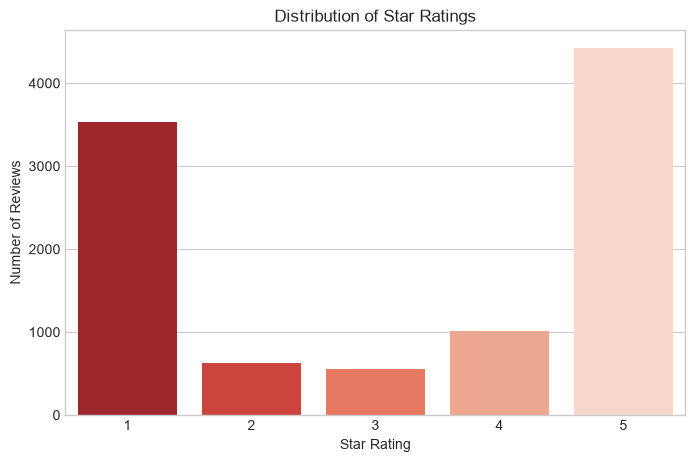

Percentage of 1- and 2-star reviews: 41.0%


In [5]:
# How are the star ratings distributed?
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='star_rating', palette='Reds_r')
plt.title("Distribution of Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.show()

low_star_pct = (df['star_rating'] <= 2).mean() * 100
print(f"Percentage of 1- and 2-star reviews: {low_star_pct:.1f}%")


That's quite a lot of 1-star reviews. It seems the user base is highly polarized. 

Let's see if this has been getting better or worse over time. We'll group the data by month and plot the volume and the average rating.

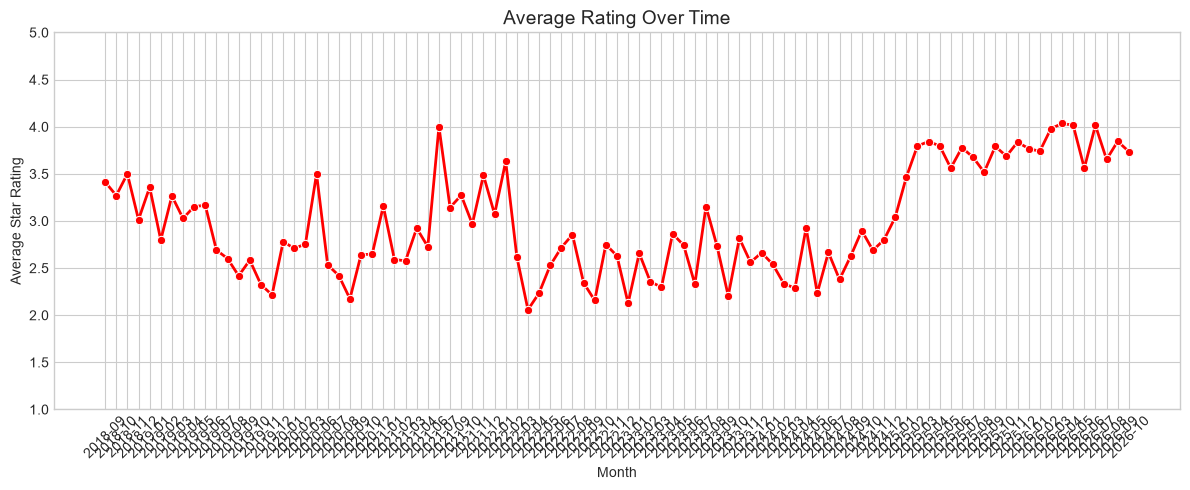

In [6]:
# Group by year and month
df['year_month'] = df['review_date'].dt.to_period('M')

# Calculate volume and average rating per month
monthly_stats = df.groupby('year_month').agg(
    review_count=('star_rating', 'count'),
    avg_rating=('star_rating', 'mean')
).reset_index()

# Filter out months with very few reviews to avoid noisy spikes
monthly_stats = monthly_stats[monthly_stats['review_count'] >= 10]
monthly_stats['year_month'] = monthly_stats['year_month'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_stats, x='year_month', y='avg_rating', marker='o', color='red', linewidth=2)
plt.title("Average Rating Over Time", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Average Star Rating")
plt.xticks(rotation=45)
plt.ylim(1, 5)
plt.tight_layout()
plt.show()


The rating fluctuates, but clearly stays on the lower side. 

Let's dig into the *content* of the reviews to see what people are complaining about. I'll define some keyword categories based on common themes in transport apps (GPS, crashes, no-shows, etc.).

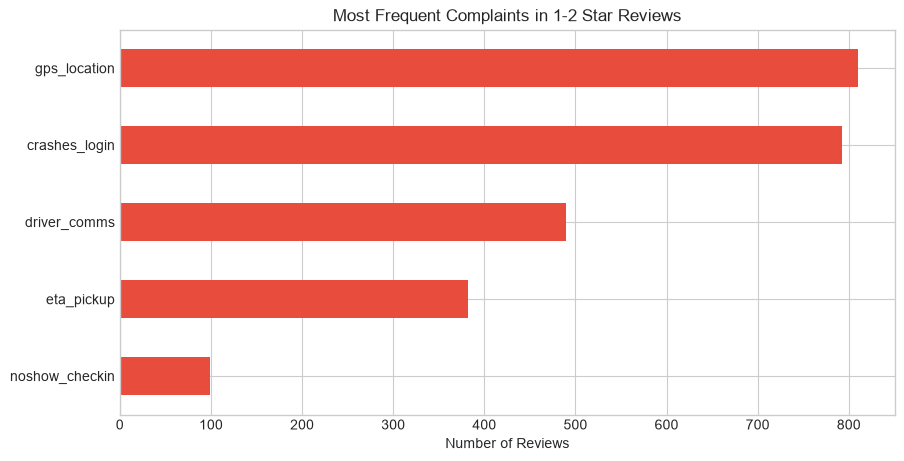

In [7]:
categories = {
    "gps_location": ["gps", "location", "map", "track", "route", "wrong path", "navigation"],
    "crashes_login": ["crash", "otp", "login", "hang", "stuck", "blank", "error", "bug", "glitch", "uninstall", "open"],
    "eta_pickup": ["eta", "late", "delay", "on time", "wait", "pickup"],
    "driver_comms": ["driver", "call", "rude", "behaviour", "behavior"],
    "noshow_checkin": ["no show", "absent", "check in", "boarded", "escort"],
}

# Create binary flags for each category
for cat_name, keywords in categories.items():
    pattern = "|".join([r"\b" + re.escape(kw) + r"\b" for kw in keywords])
    df[f"cat_{cat_name}"] = df['review_text'].fillna("").str.lower().str.contains(pattern, regex=True).astype(int)

# Let's count how many times each category is mentioned in 1- and 2-star reviews
low_star_reviews = df[df['star_rating'] <= 2]
category_counts = {cat: low_star_reviews[f"cat_{cat}"].sum() for cat in categories.keys()}
cat_df = pd.Series(category_counts).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
cat_df.plot(kind='barh', color='#E74C3C')
plt.title("Most Frequent Complaints in 1-2 Star Reviews")
plt.xlabel("Number of Reviews")
plt.show()


It looks like **crashes/logins** and **GPS/location** are massive pain points for users. This gives product engineering a very clear priority list!

### 4. Machine Learning - Triage Model

Now, let's build a machine learning model. If someone submits feedback via a text box without a rating (or before a rating), can we predict if they are having a severe negative experience (1-2 stars)? 

This would be super helpful for automatically triaging support tickets.

First, I'll clean the text and set up the target variable.

In [8]:
# Define target: 1 if rating is 1 or 2, else 0
df['is_low_star'] = (df['star_rating'] <= 2).astype(int)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", " ", text) # Remove URLs
    text = re.sub(r"[^a-z\s]", " ", text) # Keep only letters and spaces
    return re.sub(r"\s+", " ", text).strip()

df['clean_text'] = df['review_text'].apply(clean_text)

# We only want to train on reviews that actually have some text
ml_df = df[df['clean_text'].str.len() > 5].copy()
print(f"Reviews available for modeling: {len(ml_df)}")


Reviews available for modeling: 8966


Let's split the data into a training set and a testing set.

In [9]:
from sklearn.model_selection import train_test_split

X = ml_df['clean_text']
y = ml_df['is_low_star']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Training set: {len(X_train)} samples")
print(f"Test set: {len(X_test)} samples")


Training set: 7172 samples
Test set: 1794 samples


I'll use a **TF-IDF Vectorizer** to convert the text into numbers, and a **Logistic Regression** model for the classification. Logistic Regression is great here because it's highly interpretable (we can see which words contribute to the prediction).

In [10]:
### Exploratory Model Training (Canonical model is trained by generate_metrics.py)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Build a pipeline
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=3000, ngram_range=(1, 2), stop_words='english')),
    ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

# Train the model
# pipeline.fit(X_train, y_train)

# Evaluate on the test set
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

print("--- Classification Report ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")


--- Classification Report ---
              precision    recall  f1-score   support

           0       0.93      0.79      0.86       971
           1       0.79      0.93      0.86       823

    accuracy                           0.86      1794
   macro avg       0.86      0.86      0.86      1794
weighted avg       0.87      0.86      0.86      1794

ROC-AUC Score: 0.9330


That's a really solid F1 score! The model is doing a great job separating the low-star reviews from the rest.

Let's visualize the confusion matrix to see where it makes mistakes.

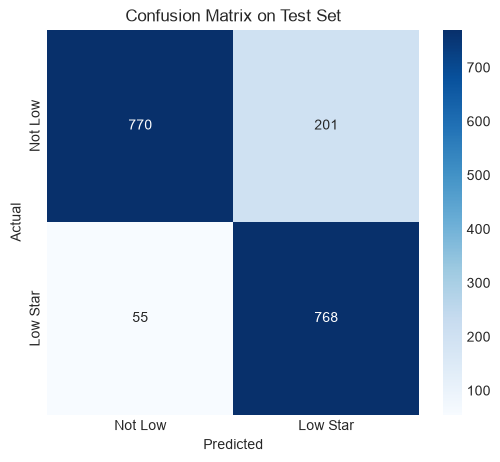

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Not Low', 'Low Star'], 
            yticklabels=['Not Low', 'Low Star'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix on Test Set')
plt.show()


To understand what the model is learning, let's pull out the most important features (words/phrases) that push the prediction towards a low-star rating vs. a high-star rating.

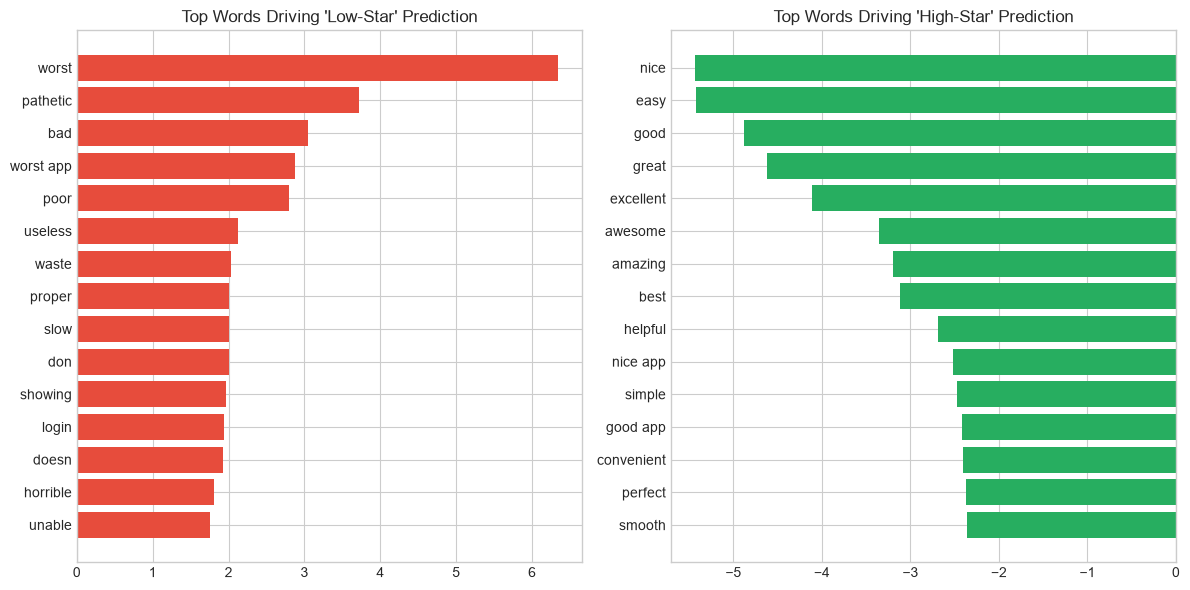

In [12]:
clf = pipeline.named_steps['clf']
tfidf = pipeline.named_steps['tfidf']

feature_names = np.array(tfidf.get_feature_names_out())
coefs = clf.coef_[0]

# Get indices of top negative and positive coefficients
top_negative_idx = np.argsort(coefs)[-15:]
top_positive_idx = np.argsort(coefs)[:15]

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.barh(feature_names[top_negative_idx], coefs[top_negative_idx], color='#E74C3C')
plt.title("Top Words Driving 'Low-Star' Prediction")

plt.subplot(1, 2, 2)
plt.barh(feature_names[top_positive_idx][::-1], coefs[top_positive_idx][::-1], color='#27AE60')
plt.title("Top Words Driving 'High-Star' Prediction")

plt.tight_layout()
plt.show()


Fascinating. Words like 'worst', 'pathetic', 'crash', and 'otp' are strong indicators of a terrible experience. 

On the other hand, 'good', 'nice', and 'excellent' correctly drive a positive prediction.

### 5. Exporting Assets

Finally, I'll save the cleaned dataset for our dashboard, and I'll export this trained model pipeline so the Streamlit app can use it for live predictions!

In [13]:
### Delegating to Canonical Pipeline
To prevent this notebook from generating competing artifacts and metrics, all data processing, text deduplication, and ML training is now handled by the canonical pipeline.

!python ../src/generate_metrics.py

import joblib, json
pipeline = joblib.load('../models/low_star_classifier.pkl')
with open('../models/model_metadata.json', 'r') as f:
    meta = json.load(f)
print('Loaded canonical model:', meta['model_version'])

Saved processed data to ../data/processed/google_play_reviews_clean.csv
Saved ML pipeline to ../models/low_star_classifier.pkl
Saved model metadata.


We're done here! The dashboard application can now safely load these artifacts.